# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)
random.seed(1234)  # Đồng bộ seed cho random_tour(), vốn dùng random.shuffle()


In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[2, 8, 3, 5, 6, 4, 9, 0, 1, 7]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])}")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.873881857725191)

Tour length: 5.87


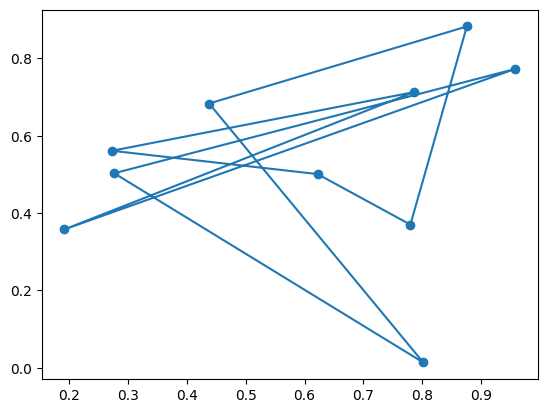

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

### Bài 7 — Quy ước chung

Các ví dụ gốc của giảng viên được giữ lại; bổ sung Python `random.seed(1234)` vì hàm `random_tour()` dùng `random.shuffle` ngoài NumPy. Mọi thuật toán bên dưới dùng toán tử swap (hoán đổi hai vị trí thành phố). `max_steps` giới hạn số cải thiện được chấp nhận; First-choice và SA có thêm ngân sách lần thử; Random Restarts đếm cả khởi tạo ban đầu trong số lượt thử. Mỗi hàm trả về một dictionary để thống nhất phép đo và kiểm tra tính hợp lệ của tour.

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (swap any two distinct city positions in the tour) and always choose the best among all local moves.

In [6]:
from itertools import combinations
from time import perf_counter

# Toán tử lân cận dùng CHUNG cho cả 5 phương pháp: swap (i, j), 0 <= i < j < n.
def swap_neighbor(tour, i, j):
    neighbor = list(tour)
    neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
    return neighbor


def all_swap_neighbors(tour):
    for i, j in combinations(range(len(tour)), 2):
        yield swap_neighbor(tour, i, j)


def check_tour(tsp, tour):
    n = len(tsp['dist'])
    assert len(tour) == n and sorted(tour) == list(range(n)), 'Tour không phải hoán vị hợp lệ'


def _pack_result(algorithm, start_tour, initial_cost, best_tour, best_cost,
                 trace, iterations, evaluations, elapsed_ms, **extra):
    return dict(algorithm=algorithm, initial_tour=list(start_tour),
                initial_cost=float(initial_cost), tour=list(best_tour),
                cost=float(best_cost), best_cost=float(best_cost),
                improvements=int(iterations), evaluations=int(evaluations),
                runtime_ms=float(elapsed_ms), trace=list(trace), **extra)


def steepest_ascent_tsp(tsp, start_tour, max_steps=100):
    """Chọn lân cận swap có tour_length nhỏ nhất; dừng khi không cải thiện."""
    t0 = perf_counter()
    current = list(start_tour)
    initial_cost = cost = tour_length(tsp, current)
    evaluations, iterations = 1, 0
    trace = [float(cost)]
    while iterations < max_steps:
        best_neighbor, neighbor_cost = None, cost
        for candidate in all_swap_neighbors(current):
            new_cost = tour_length(tsp, candidate)
            evaluations += 1
            if new_cost < neighbor_cost - 1e-12:
                neighbor_cost, best_neighbor = new_cost, candidate
        if best_neighbor is None:
            break
        current, cost = best_neighbor, neighbor_cost
        trace.append(float(cost))
        iterations += 1
    return _pack_result('Steepest-ascent', start_tour, initial_cost,
                        current, cost, trace, iterations, evaluations,
                        (perf_counter()-t0)*1000)

# Kiểm tra số láng giềng và tính hợp lệ của toán tử swap.
assert len(list(all_swap_neighbors(list(range(6))))) == 15
assert all(sorted(t) == list(range(6)) for t in all_swap_neighbors(list(range(6))))


## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

In [7]:
def random_restart_tsp(tsp, start_tour, restarts=8, max_steps=100, seed=20261015):
    """Tối đa restarts lượt khởi tạo (gồm start_tour lần đầu); giữ tour tốt nhất."""
    t0 = perf_counter()
    rng = random.Random(seed)
    initial_cost = tour_length(tsp, start_tour)
    best_tour, best_cost = list(start_tour), initial_cost
    evaluations, improvements = 0, 0
    trace, subruns = [float(best_cost)], []
    for run_idx in range(restarts):
        candidate_start = list(start_tour) if run_idx == 0 else rng.sample(range(len(start_tour)), len(start_tour))
        res = steepest_ascent_tsp(tsp, candidate_start, max_steps=max_steps)
        evaluations += res['evaluations']
        improvements += res['improvements']
        if res['cost'] < best_cost - 1e-12:
            best_tour, best_cost = list(res['tour']), res['cost']
        trace.append(float(best_cost))
        subruns.append({'attempt':run_idx+1, 'initial_cost':res['initial_cost'], 'cost':res['cost']})
    return _pack_result('Random Restarts', start_tour, initial_cost,
                        best_tour, best_cost, trace, improvements, evaluations,
                        (perf_counter()-t0)*1000, attempts=restarts,
                        restarts=max(0,restarts-1), subruns=subruns)


## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

In [8]:
def stochastic_hill_climbing_tsp(tsp, start_tour, seed=20261015, max_steps=100):
    """Đánh giá TẤT CẢ swap, chọn ngẫu nhiên một lân cận cải thiện."""
    t0 = perf_counter()
    rng = random.Random(seed)
    current = list(start_tour)
    initial_cost = cost = tour_length(tsp, current)
    evaluations, iterations = 1, 0
    trace = [float(cost)]
    while iterations < max_steps:
        improving = []
        for candidate in all_swap_neighbors(current):
            new_cost = tour_length(tsp, candidate)
            evaluations += 1
            if new_cost < cost - 1e-12:
                improving.append((candidate, new_cost))
        if not improving:
            break
        current, cost = rng.choice(improving)
        iterations += 1
        trace.append(float(cost))
    return _pack_result('Stochastic (all)', start_tour, initial_cost,
                        current, cost, trace, iterations, evaluations,
                        (perf_counter()-t0)*1000)


## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

In [9]:
def first_choice_hill_climbing_tsp(tsp, start_tour, seed=20261015,
                                   max_steps=100, max_no_improve=None,
                                   max_evaluations=3000):
    """Sinh swap ngẫu nhiên, chấp nhận ngay nếu cải thiện; dừng theo ngân sách thử."""
    t0 = perf_counter()
    rng = random.Random(seed)
    current = list(start_tour)
    initial_cost = cost = tour_length(tsp, current)
    n = len(current)
    if max_no_improve is None:
        max_no_improve = min(n*(n-1), 250)
    evaluations, improvements, failures = 1, 0, 0
    trace = [float(cost)]
    while (improvements < max_steps and failures < max_no_improve
           and evaluations-1 < max_evaluations):
        i, j = rng.sample(range(n), 2)
        neighbor = swap_neighbor(current, i, j)
        new_cost = tour_length(tsp, neighbor)
        evaluations += 1
        if new_cost < cost - 1e-12:
            current, cost = neighbor, new_cost
            improvements += 1
            failures = 0
            trace.append(float(cost))
        else:
            failures += 1
    # Hết ngân sách lấy mẫu KHÔNG chứng minh trạng thái là local optimum.
    return _pack_result('First-choice', start_tour, initial_cost,
                        current, cost, trace, improvements, evaluations,
                        (perf_counter()-t0)*1000, failed_trials=failures)


## Simulated Annealing [2 Points]

In [10]:
def simulated_annealing_tsp(tsp, start_tour, seed=20261015, T0=0.20,
                            alpha=0.995, max_iterations=1500, min_T=1e-8):
    """SA với swap; trả nghiệm tốt nhất từng gặp, không chỉ trạng thái cuối."""
    assert T0 > 0 and 0 < alpha < 1 and max_iterations > 0
    t0 = perf_counter()
    rng = random.Random(seed)
    current = list(start_tour)
    initial_cost = cost = tour_length(tsp, current)
    best_tour, best_cost = list(current), float(cost)
    trace = [float(best_cost)]
    current_trace = [float(cost)]
    evaluations, accepted, accepted_worse = 1, 0, 0
    for step in range(max_iterations):
        temperature = T0 * (alpha ** step)
        if temperature < min_T:
            break
        i, j = rng.sample(range(len(current)), 2)
        candidate = swap_neighbor(current, i, j)
        new_cost = tour_length(tsp, candidate)
        evaluations += 1
        delta = new_cost - cost
        # delta == 0: chấp nhận; delta > 0: exp(-delta/T).
        if delta <= 0 or rng.random() < math.exp(-delta / temperature):
            current, cost = candidate, new_cost
            accepted += 1
            if delta > 1e-12:
                accepted_worse += 1
        if cost < best_cost - 1e-12:
            best_tour, best_cost = list(current), float(cost)
        trace.append(float(best_cost))
        current_trace.append(float(cost))
    return _pack_result('Simulated Annealing', start_tour, initial_cost,
                        best_tour, best_cost, trace, accepted, evaluations,
                        (perf_counter()-t0)*1000,
                        accepted_worse=accepted_worse, attempts=evaluations-1,
                        current_trace=current_trace)


## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [11]:
# Dùng perf_counter() (đồng hồ độ phân giải cao) trong các hàm đã cài đặt để đo runtime_ms.
from time import perf_counter


In [12]:
from pathlib import Path
results_dir = Path('Lab03_Bai7_Results')
results_dir.mkdir(exist_ok=True)

# 1) Một bài toán minh họa: TẤT CẢ phương pháp dùng cùng TSP và start_tour.
seed_demo = 20261015
random.seed(seed_demo)
np.random.seed(seed_demo)
tsp_demo = random_tsp(12)
initial_demo = random_tour(12)
check_tour(tsp_demo, initial_demo)

methods = {
    'Steepest-ascent': lambda t, x, seed: steepest_ascent_tsp(t, x),
    'Random Restarts': lambda t, x, seed: random_restart_tsp(t, x, restarts=8, seed=seed),
    'Stochastic (all)': lambda t, x, seed: stochastic_hill_climbing_tsp(t, x, seed=seed),
    'First-choice': lambda t, x, seed: first_choice_hill_climbing_tsp(t, x, seed=seed),
    'Simulated Annealing': lambda t, x, seed: simulated_annealing_tsp(t, x, seed=seed),
}

demo_results = {name: method(tsp_demo, initial_demo, seed_demo)
                for name, method in methods.items()}
for name, res in demo_results.items():
    check_tour(tsp_demo, res['tour'])
    assert abs(tour_length(tsp_demo, res['tour']) - res['cost']) < 1e-9
    assert res['cost'] <= res['initial_cost'] + 1e-9

demo_df = pd.DataFrame([
    {'algorithm':name, 'initial_cost':res['initial_cost'],
     'best_cost':res['cost'], 'improvement_pct':100*(1-res['cost']/res['initial_cost']),
     'accepted_steps':res['improvements'], 'evaluations':res['evaluations'],
     'time_ms':res['runtime_ms']}
    for name, res in demo_results.items()
])
print('Minh họa n=12, seed=', seed_demo)
print(demo_df.round(3).to_string(index=False))
demo_df.to_csv(results_dir/'Bai7_TSP_Demo.csv', index=False)

# 2) Thực nghiệm đa kích thước, nhiều seed, cùng bài toán và cùng tour đầu cho mọi thuật toán.
rows = []
sizes = [6, 10, 15, 20, 25]
trials = 5
for n in sizes:
    for trial in range(trials):
        seed = 20261015 + n*100 + trial
        np.random.seed(seed)
        random.seed(seed)
        tsp_i = random_tsp(n)
        init_i = random_tour(n)
        for name, run in methods.items():
            res = run(tsp_i, init_i, seed)
            check_tour(tsp_i, res['tour'])
            assert abs(tour_length(tsp_i, res['tour']) - res['cost']) < 1e-9
            rows.append({'n':n, 'trial':trial+1, 'seed':seed,
                         'algorithm':name, 'initial_cost':res['initial_cost'],
                         'best_cost':res['cost'],
                         'improvement_pct':100*(1-res['cost']/res['initial_cost']),
                         'accepted_steps':res['improvements'],
                         'evaluations':res['evaluations'],
                         'time_ms':res['runtime_ms']})

trial_df = pd.DataFrame(rows)
summary_df = trial_df.groupby(['n','algorithm'], as_index=False).agg(
    mean_initial_cost=('initial_cost','mean'),
    mean_best_cost=('best_cost','mean'),
    best_observed_cost=('best_cost','min'),
    mean_improvement_pct=('improvement_pct','mean'),
    mean_time_ms=('time_ms','mean'),
    mean_evaluations=('evaluations','mean'),
    trials=('trial','count')
)
trial_df.to_csv(results_dir/'Bai7_TSP_Trials.csv', index=False)
summary_df.to_csv(results_dir/'Bai7_TSP_Summary.csv', index=False)
print()
print('Tổng hợp',len(trial_df),'lượt (5 thuật toán × 5 kích thước × 5 lần):')
print(summary_df.round(3).to_string(index=False))


Minh họa n=12, seed= 20261015
          algorithm  initial_cost  best_cost  improvement_pct  accepted_steps  evaluations  time_ms
    Steepest-ascent          7.18       2.97            58.67               8          595     1.07
    Random Restarts          7.18       2.97            58.67              62         4628     9.27
   Stochastic (all)          7.18       2.97            58.67              19         1321     3.42
       First-choice          7.18       2.97            58.67              13          391     1.59
Simulated Annealing          7.18       2.97            58.67              42         1501     5.44



Tổng hợp 125 lượt (5 thuật toán × 5 kích thước × 5 lần):
 n           algorithm  mean_initial_cost  mean_best_cost  best_observed_cost  mean_improvement_pct  mean_time_ms  mean_evaluations  trials
 6        First-choice               3.04            2.32                1.60                 23.04          0.15              59.8       5
 6     Random Restarts               3.04            2.25                1.26                 26.65          0.50             383.0       5
 6 Simulated Annealing               3.04            2.25                1.26                 26.65          4.40            1501.0       5
 6     Steepest-ascent               3.04            2.25                1.26                 26.65          0.07              55.0       5
 6    Stochastic (all)               3.04            2.28                1.26                 25.78          0.09              73.0       5
10        First-choice               4.94            3.08                2.48                 34.85   

### Bài 7 — Mô hình hóa và thiết kế thí nghiệm

Một trạng thái là hoán vị các thành phố `tour = [π₀, …, πₙ₋₁]`. Mỗi thành phố được thăm đúng một lần, sau đó quay về thành phố đầu. Hàm mục tiêu cần tối thiểu hóa là

\[
f(\pi)=\sum_{i=0}^{n-2}d_{\pi_i,\pi_{i+1}}+d_{\pi_{n-1},\pi_0}.
\]

Để thống nhất với mô tả **Exchange two cities** của notebook gốc, toàn bộ năm thuật toán dùng cùng một toán tử **swap (i,j)**: hoán đổi hai vị trí khác nhau, không thêm hoặc mất thành phố. Một tour có `n(n−1)/2` lân cận theo toán tử này. Ví dụ `tour=[0,1,2,3]`, swap `(1,3)` cho `[0,3,2,1]`.

Steepest-ascent và Stochastic (all) duyệt toàn bộ lân cận mỗi bước; First-choice chỉ sinh ngẫu nhiên từng lân cận. Random Restarts áp dụng lại Steepest-ascent từ những tour khởi tạo khác nhau, còn Simulated Annealing có thể chấp nhận một bước làm *tăng* độ dài tour. Mỗi lần chạy đều trả về **tour tốt nhất** đã tìm thấy. Random seed và ngân sách được cố định, nhưng Random Restarts tiêu tốn nhiều lần tìm kiếm hơn các thuật toán một lần khởi tạo nên kết quả thời gian không thể hiểu là so sánh cùng ngân sách đánh giá.

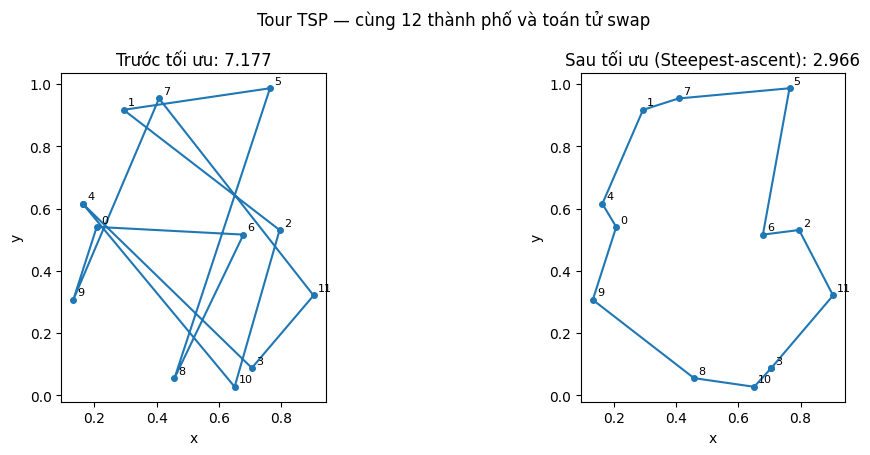

In [13]:
# 3) Tour trước / sau khi tối ưu trên cùng tập thành phố.
chosen_name = min(demo_results, key=lambda name: demo_results[name]['cost'])
chosen = demo_results[chosen_name]

def plot_tour(ax, tsp, tour, title):
    xy = tsp['pos'][['x','y']].to_numpy()
    closed = list(tour) + [tour[0]]
    ax.plot(xy[closed,0], xy[closed,1], '-o', linewidth=1.5, markersize=4)
    for city, (x,y) in enumerate(xy):
        ax.annotate(str(city), (x,y), xytext=(3,3), textcoords='offset points', fontsize=8)
    ax.set(title=title, xlabel='x', ylabel='y')
    ax.set_aspect('equal', adjustable='box')

fig, axes = plt.subplots(1,2,figsize=(11,4.6))
plot_tour(axes[0], tsp_demo, initial_demo, f'Trước tối ưu: {tour_length(tsp_demo,initial_demo):.3f}')
plot_tour(axes[1], tsp_demo, chosen['tour'], f'Sau tối ưu ({chosen_name}): {chosen["cost"]:.3f}')
fig.suptitle('Tour TSP — cùng 12 thành phố và toán tử swap')
fig.tight_layout()
fig.savefig(results_dir/'Bai7_TSP_Tour_Before_After.png',dpi=160,bbox_inches='tight')
plt.show()


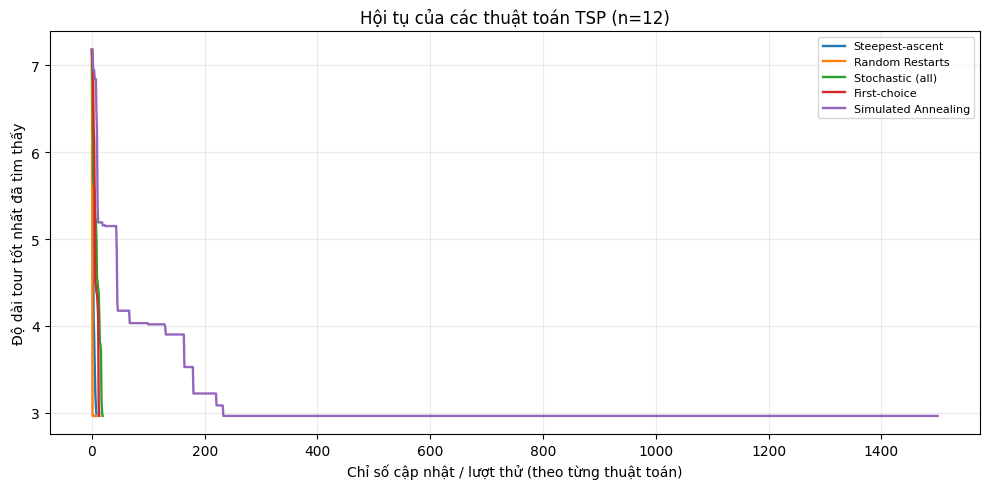

In [14]:
# 4) Đường hội tụ: chi phí tốt nhất đã tìm thấy.
plt.figure(figsize=(10,5))
for name,res in demo_results.items():
    plt.plot(range(len(res['trace'])), res['trace'],label=name,linewidth=1.7)
plt.xlabel('Chỉ số cập nhật / lượt thử (theo từng thuật toán)')
plt.ylabel('Độ dài tour tốt nhất đã tìm thấy')
plt.title('Hội tụ của các thuật toán TSP (n=12)')
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(results_dir/'Bai7_TSP_Convergence.png',dpi=160,bbox_inches='tight')
plt.show()


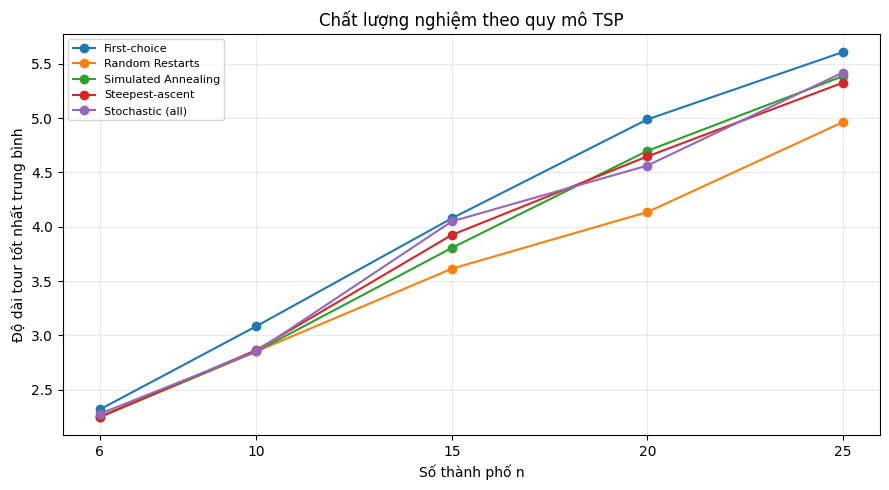

In [15]:
# 5) Độ dài tour tốt nhất (trung bình nhiều seed) theo n.
plt.figure(figsize=(9,5))
for name,grp in summary_df.groupby('algorithm'):
    plt.plot(grp['n'],grp['mean_best_cost'],marker='o',label=name)
plt.xlabel('Số thành phố n')
plt.ylabel('Độ dài tour tốt nhất trung bình')
plt.title('Chất lượng nghiệm theo quy mô TSP')
plt.xticks(sizes)
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(results_dir/'Bai7_TSP_Quality_vs_N.png',dpi=160,bbox_inches='tight')
plt.show()


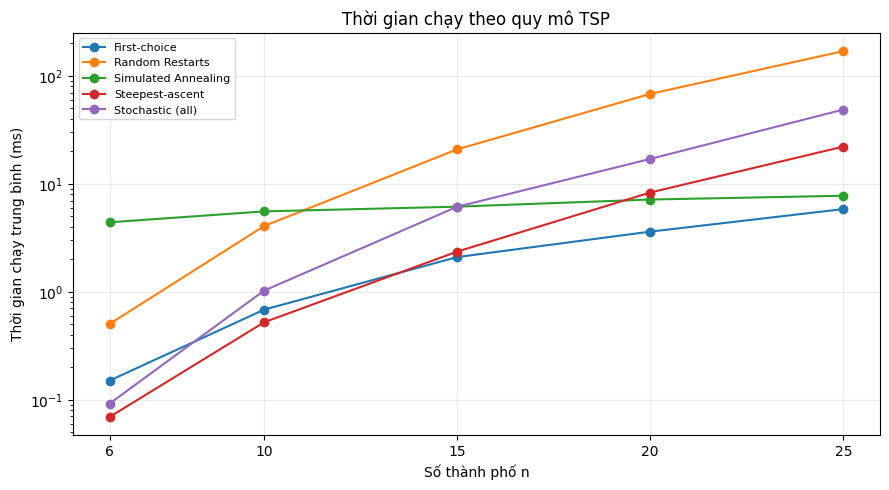

In [16]:
# 6) Thời gian thực thi trung bình, đơn vị ms.
plt.figure(figsize=(9,5))
for name,grp in summary_df.groupby('algorithm'):
    plt.plot(grp['n'],grp['mean_time_ms'],marker='o',label=name)
plt.xlabel('Số thành phố n')
plt.ylabel('Thời gian chạy trung bình (ms)')
plt.title('Thời gian chạy theo quy mô TSP')
plt.xticks(sizes)
plt.yscale('log')
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(results_dir/'Bai7_TSP_Runtime_vs_N.png',dpi=160,bbox_inches='tight')
plt.show()


### Nhận xét thực nghiệm (đọc sau khi chạy)

- Theo đề bài, mục tiêu là **độ dài chu trình khép kín**, không phải tìm một đường đi chỉ đi qua các thành phố mà không quay về điểm đầu. `tour_length()` đã cộng cạnh cuối quay về thành phố đầu tiên.
- Steepest-ascent lựa chọn bước cải thiện tốt nhất trong tất cả lân cận nhưng có thể bị kẹt tại cực tiểu cục bộ; Stochastic (all) chọn ngẫu nhiên trong tập lân cận cải thiện, nên số bước và chất lượng kết quả phụ thuộc seed.
- First-choice có thể cần ít phép đánh giá khi sớm gặp bước cải thiện, nhưng điều kiện dừng theo số lần thử không chứng minh toàn bộ lân cận đều không cải thiện. Random Restarts thường cải thiện cơ hội gặp tour tốt nhưng phải trả giá bằng nhiều lượt chạy.
- Simulated Annealing dùng \(\Delta=f(\text{mới})-f(\text{hiện tại})\). Với \(\Delta>0\), bước xấu được chấp nhận với xác suất \(\exp(-\Delta/T)\); lưu riêng nghiệm tốt nhất tránh đánh mất kết quả tốt khi thuật toán chuyển sang tour dài hơn.
- Các biểu đồ dựa trên nhiều seed nên có giá trị minh họa xu hướng trong ngân sách đã chọn, **không chứng minh** tìm thấy tour tối ưu toàn cục. Không so sánh trục x của đồ thị hội tụ như số lần gọi hàm mục tiêu tương đương: mỗi thuật toán ghi `trace` theo một quy ước khác nhau.
- Thời gian được đo bằng `perf_counter()` trên một lượt chạy và tính trung bình qua năm lần tạo bài toán; chịu ảnh hưởng của CPU, phiên bản Python, trạng thái máy và cách cài đặt. `mean_evaluations` trong CSV là chỉ số bổ trợ để giải thích chi phí tính toán.

**Kết luận:** Cùng một toán tử swap tạo cơ sở đánh giá công bằng về mô hình lân cận. Không có một thuật toán luôn tốt nhất về cả chất lượng tour và chi phí chạy; lựa chọn cần cân nhắc số thành phố, ngân sách và yêu cầu chất lượng. Genetic Algorithm trong notebook là phần bonus và không được thực hiện trong Bài 7 này.

## Bonus: Genetic Algorithm [+1 Point]

In [17]:
# Bonus — Genetic Algorithm: không bắt buộc theo tài liệu Lab03; chưa triển khai.
